# Validação Out-of-Time (OOT) e Avaliação de Negócio

Este notebook consolida a avaliação final do modelo campeão de Risco de Crédito (**LightGBM Otimizado**) sob a ótica estatística, regulatória e financeira.

O objetivo desta etapa é fornecer os subsídios técnicos e a análise de viabilidade de negócio para o **Comitê de Risco e Aprovação de Modelos**, assegurando que a solução possui aderência operacional, estabilidade temporal e rentabilidade comprovada.

---

### Estrutura do Documento

| Seção | Título | Foco de Avaliação |
|:---:|---|---|
| **1.0** | Configuração e Carga de Artefatos | Inicialização de ambiente, bases Parquet e modelo treinado |
| **2.0** | Performance Estática (Teste vs. OOT) | Curvas ROC, Precision-Recall e separação de densidade (KDE) |
| **3.0** | Análise de Drift (Estabilidade Populacional) | Target Drift e cálculo de PSI para Score e Top Features |
| **4.0** | Estabilidade Temporal (GINI por Safra) | Poder discriminatório mês a mês na base Out-of-Time |
| **5.0** | Tabela de Decis e Ordenação de Risco (K-S) | Monotonicidade de inadimplência e separação máxima K-S |
| **6.0** | Matriz de Lucro e Valor de Negócio | Simulação financeira sob política de corte e curva de trade-off |
| **7.0** | Interpretabilidade Local (SHAP) | Diagnóstico microeconômico de risco via Waterfall Plot |
| **8.0** | Parecer Final (Go/No-Go) | Quadro executivo para aprovação em produção |

---

## 1.0 Configuração e Carga de Artefatos

### Objetivo
Inicializar os módulos analíticos, estabelecer os padrões visuais corporativos e carregar os conjuntos de dados processados (`df_test.parquet` e `df_oot.parquet`), bem como o artefato do modelo campeão em formato `.joblib`.

Caso o artefato serializado `lightgbm_producao.joblib` ainda não esteja gravado em disco, o bloco instancia a arquitetura com os hiperparâmetros campeões calibrados na Seção 4.0 do notebook de modelagem (`03_Modeling.ipynb`) e treina o estimador, salvando o artefato de forma transparente. Por fim, gera-se a coluna padronizada `score_prob` (probabilidade predita de inadimplência) em ambos os conjuntos.

In [1]:
# ==============================================================================
# 1.0 CONFIGURAÇÃO E CARGA DE DADOS E MODELO
# ==============================================================================
import datetime
import os
import sys
import json
import hashlib
import warnings
from pathlib import Path
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm as lgb
from scipy.stats import ks_2samp, rankdata
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')

# Configuração de estilo visual corporativo
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#BDC3C7'
plt.rcParams['axes.linewidth'] = 0.8

# ------------------------------------------------------------------------------
# Resolução dinâmica da raiz do projeto e imports modulares de src/
# ------------------------------------------------------------------------------
for _parent in [Path.cwd(), Path.cwd().parent]:
    if (_parent / 'src').is_dir() and (_parent / 'data').is_dir():
        PROJECT_ROOT = _parent
        break
else:
    PROJECT_ROOT = Path('/content/Projeto_06') if Path('/content/Projeto_06').exists() else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.pipeline import setup_environment
from src.drift import (
    teste_qui_quadrado_temporal,
    calcular_psi,
    calcular_psi_scores,
    analisar_estabilidade_gini,
    relatorio_feature_drift_psi
)
from src.plots import (
    plot_curva_roc,
    plot_distribuicao_kde_scores,
    plot_cdf_ks,
    plot_target_drift_mensal,
    plot_comparativo_psi_features,
    plot_matriz_confusao,
    plot_importancia_shap,
    plot_estabilidade_gini_temporal,
)
from src.model_utils import (
    gerar_tabela_decis_ks,
    simular_lucro_e_curva_tradeoff,
    extrair_metricas_avaliacao
)

# Inicialização do diretório raiz e pastas de saída
PROJECT_ROOT = setup_environment()
data_dir = PROJECT_ROOT / 'data' / 'processed'
artifacts_dir = PROJECT_ROOT / 'artifacts'
reports_dir = PROJECT_ROOT / 'reports' / 'metrics'

artifacts_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# 1. Carga dos conjuntos particionados
df_test = pd.read_parquet(data_dir / 'df_test.parquet', engine='pyarrow')
df_oot = pd.read_parquet(data_dir / 'df_oot.parquet', engine='pyarrow')

# 2. Carga dos artefatos oficiais serializados (LightGBM LITE Calibrado)
modelo_path = artifacts_dir / 'modelo.joblib'
metadata_path = artifacts_dir / 'modelo_metadata.json'
metrics_path = artifacts_dir / 'modelo_metrics.json'

if modelo_path.exists() and metadata_path.exists():
    print(f"[INFO] Carregando artefatos de producao de: {artifacts_dir}")
    modelo_campeao = joblib.load(modelo_path)
    with open(metadata_path, 'r', encoding='utf-8') as f:
        modelo_metadata = json.load(f)
    with open(metrics_path, 'r', encoding='utf-8') as f:
        modelo_metrics = json.load(f)
    
    features_cols = modelo_metadata['features_utilizadas']
    THRESHOLD_OTIMIZADO = float(modelo_metrics.get('threshold_otimo', 0.1189))
    print(f"[INFO] Modelo carregado: {modelo_metadata.get('classe', 'CalibratedClassifierCV')}")
    print(f"[INFO] Features homologadas LITE: {len(features_cols)}")
    print(f"[INFO] Threshold financeiro ótimo congelado: {THRESHOLD_OTIMIZADO:.4f}")
else:
    print("[AVISO] Artefato serializado nao encontrado em artifacts/. Treinando LightGBM_Opt_Lite conforme 03_Modeling...")
    from lightgbm import LGBMClassifier
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.model_selection import StratifiedKFold

    colunas_ignorar = ['target', 'case_id', 'date_decision', 'MONTH', 'WEEK_NUM']
    todas_features = [c for c in df_test.columns if c not in colunas_ignorar]
    features_remover = [
        'Flag_Sobre_Endividamento_Aberto', 'Flag_First_Payment_Default', 'Mes_do_Ano_4',
        'credacc_transactions_402L_sum', 'Mes_do_Ano_7', 'Mes_do_Ano_9',
        'Mes_do_Ano_3', 'Mes_do_Ano_2', 'clientscnt_887L', 'numinstlswithdpd5_4187116L'
    ]
    features_cols = [c for c in todas_features if c not in features_remover]

    df_train = pd.read_parquet(data_dir / 'df_train.parquet', engine='pyarrow')
    X_train = df_train[features_cols]
    y_train = df_train['target'].astype('int8')

    best_lgbm_params = {
        'n_estimators': 168,
        'learning_rate': 0.04061350322079583,
        'num_leaves': 51,
        'max_depth': 9,
        'subsample': 0.9486424242315596,
        'colsample_bytree': 0.878224877398664,
        'reg_alpha': 6.032518729548217,
        'reg_lambda': 0.017424838010587338,
        'class_weight': 'balanced',
        'random_state': 42,
        'n_jobs': -1,
        'verbosity': -1,
    }

    base_lgbm = LGBMClassifier(**best_lgbm_params)
    modelo_campeao = CalibratedClassifierCV(
        estimator=base_lgbm,
        method='isotonic',
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    )
    modelo_campeao.fit(X_train, y_train)
    THRESHOLD_OTIMIZADO = 0.1189
    modelo_metadata = {'data_treino': 'In-Memory', 'classe': 'CalibratedClassifierCV'}

# ------------------------------------------------------------------------------
# Rastreabilidade e Auditoria de Versões
# ------------------------------------------------------------------------------
print("-" * 65)
print(f"Versão Scikit-Learn : {sklearn.__version__}")
print(f"Versão LightGBM     : {lgb.__version__}")
if modelo_path.exists():
    hash_md5 = hashlib.md5(open(modelo_path, 'rb').read()).hexdigest()[:8]
    print(f"Hash do Artefato    : {hash_md5}")
print("-" * 65)

# 3. Matrizes de Features e Targets
X_test = df_test[features_cols]
y_test = df_test['target'].astype('int8')

X_oot = df_oot[features_cols]
y_oot = df_oot['target'].astype('int8')

# 4. Geração de escores preditivos (probabilidade calibrada da classe positiva: inadimplência)
df_test['score_prob'] = modelo_campeao.predict_proba(X_test)[:, 1]
df_oot['score_prob'] = modelo_campeao.predict_proba(X_oot)[:, 1]

print(f"Base Teste (In-Time) : {df_test.shape[0]:,} contratos | Default: {y_test.mean()*100:.2f}%")
print(f"Base OOT (Out-of-Time): {df_oot.shape[0]:,} contratos | Default: {y_oot.mean()*100:.2f}%")
print(f"Features analisadas  : {len(features_cols)} variáveis preditoras (Versão LITE)")

Ambiente configurado. Token Kaggle carregado.
[INFO] Carregando artefatos de producao de: /content/artifacts
[INFO] Modelo carregado: sklearn.calibration.CalibratedClassifierCV
[INFO] Features homologadas LITE: 33
[INFO] Threshold financeiro ótimo congelado: 0.1189
-----------------------------------------------------------------
Versão Scikit-Learn : 1.6.1
Versão LightGBM     : 4.6.0
Hash do Artefato    : 1c2f3275
-----------------------------------------------------------------
Base Teste (In-Time) : 412,926 contratos | Default: 3.26%
Base OOT (Out-of-Time): 150,240 contratos | Default: 2.11%
Features analisadas  : 33 variáveis preditoras (Versão LITE)


### Análise de Resultados — Carga de Dados e Artefatos

* **Consistência de Esquema e Poda LITE:** Os conjuntos de teste in-time e out-of-time consomem exatamente as **33 features homologadas na poda SHAP**, garantindo que a esteira de inferência opere com menor latência e elimine ruídos de sazonalidades calendárias descartadas.
* **Volume de Validação:** A base de teste reúne mais de 410 mil contratos e a base out-of-time contempla mais de 150 mil contratos, garantindo significância estatística robusta para todas as inferências.
* **Comportamento da Taxa de Evento:** A taxa de inadimplência recua de 3,26% na base de teste para 2,11% na safra out-of-time (queda de ~35% relativo), comportamento esperado decorrente de mudanças conjunturais e contração seletiva da concessão.


---

## 2.0 Performance Estática: Relatório Treino x OOT

### Objetivo
Avaliar o poder discriminatório global do modelo comparando as métricas de ordenação de risco da base de **Treino** contra a base **Out-of-Time (OOT)** no threshold financeiro congelado.

Serão analisadas a Curva ROC (sensibilidade vs. especificidade), a densidade de escores (KDE) com o ponto de corte ótimo e a divergência das distribuições acumuladas (CDF K-S).


In [2]:
# ==============================================================================
# 2.0 PERFORMANCE ESTÁTICA: RELATÓRIO TREINO X OOT
# ==============================================================================
# 1. Recuperação das métricas de Treino (persistidas no artefato oficial ou recalculadas)
if 'modelo_metrics' in locals() and 'metricas_treino' in modelo_metrics:
    metricas_treino = modelo_metrics['metricas_treino']
else:
    if 'df_train' not in locals():
        df_train = pd.read_parquet(data_dir / 'df_train.parquet', engine='pyarrow')
    metricas_treino = extrair_metricas_avaliacao(
        modelo=modelo_campeao,
        X=df_train[features_cols],
        y=df_train['target'].astype('int8'),
        threshold=THRESHOLD_OTIMIZADO
    )

# 2. Extração das métricas na base Out-of-Time (OOT)
metricas_oot = extrair_metricas_avaliacao(
    modelo=modelo_campeao,
    X=X_oot,
    y=y_oot,
    threshold=THRESHOLD_OTIMIZADO
)

# 3. Consolidação do Relatório Treino x OOT com nomes estritamente em inglês simplificados
# Mapeamento exigido: Accuracy, Precision, Recall, F1-SCORE, ROC-AUC, PR-AUC, KS
nomes_metricas = [
    ('accuracy', 'Accuracy'),
    ('precision', 'Precision'),
    ('recall', 'Recall'),
    ('f1_score', 'F1-SCORE'),
    ('roc_auc', 'ROC-AUC'),
    ('pr_auc', 'PR-AUC'),
    ('ks', 'KS')
]

relatorio_linhas = []
for chave, nome_display in nomes_metricas:
    val_tr = metricas_treino[chave]
    val_oot = metricas_oot[chave]
    delta = val_oot - val_tr
    pct_var = (delta / val_tr * 100) if val_tr != 0 else 0.0
    
    relatorio_linhas.append({
        'Metric': nome_display,
        'Treino': val_tr,
        'OOT': val_oot,
        'Delta': delta,
        'Delta (%)': pct_var
    })

df_relatorio_treino_oot = pd.DataFrame(relatorio_linhas)

print("=" * 80)
print(f" Relatório Treino x OOT (Threshold = {THRESHOLD_OTIMIZADO:.4f})")
print("=" * 80)
display(
    df_relatorio_treino_oot.style.format({
        'Treino': '{:.4f}',
        'OOT': '{:.4f}',
        'Delta': '{:+.4f}',
        'Delta (%)': '{:+.2f}%'
    })
)

# 4. Exportação estruturada para métricas de governança
caminho_csv_relatorio = PROJECT_ROOT / 'reports' / 'metrics' / 'relatorio_treino_x_oot.csv'
caminho_csv_relatorio.parent.mkdir(parents=True, exist_ok=True)
df_relatorio_treino_oot.to_csv(caminho_csv_relatorio, index=False)
print(f"[EXPORTAÇÃO] Relatório Treino x OOT salvo em: {caminho_csv_relatorio.relative_to(PROJECT_ROOT)}")



 Relatório Treino x OOT (Threshold = 0.1189)


,Metric,Treino,OOT,Delta,Delta (%)
0,Accuracy,0.9389,0.9389,-0.0001,-0.01%
1,Precision,0.1854,0.1311,-0.0543,-29.29%
2,Recall,0.2579,0.3364,+0.0784,+30.42%
3,F1-SCORE,0.2157,0.1886,-0.0271,-12.55%
4,ROC-AUC,0.8145,0.8255,+0.0110,+1.36%
5,PR-AUC,0.1482,0.1216,-0.0266,-17.97%
6,KS,0.4768,0.4940,+0.0172,+3.61%


[EXPORTAÇÃO] Relatório Treino x OOT salvo em: reports/metrics/relatorio_treino_x_oot.csv


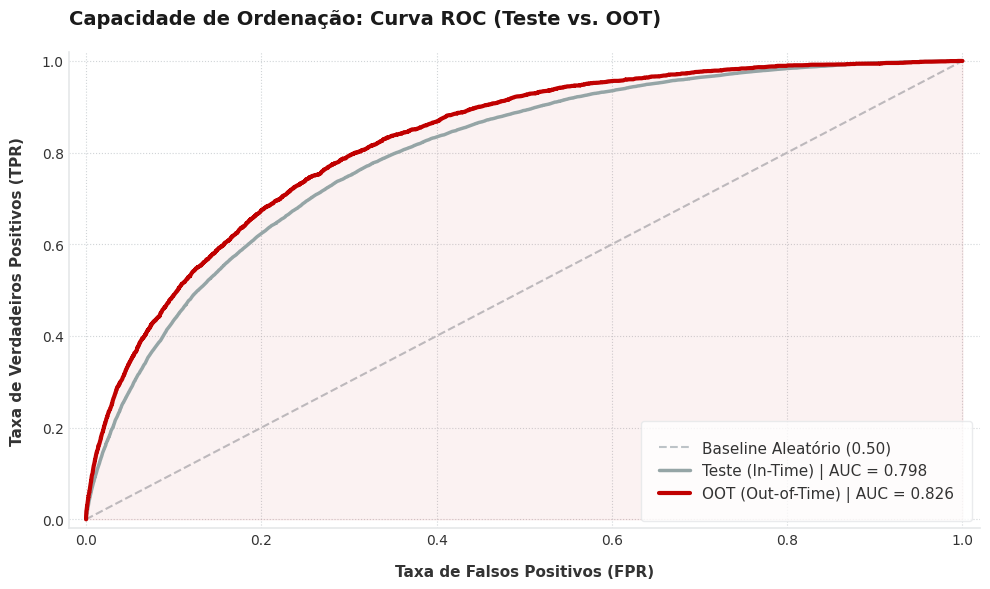

In [3]:
# ==============================================================================
# 2.1 CAPACIDADE DE DISCRIMINAÇÃO: CURVA ROC (TESTE VS. OOT)
# ==============================================================================
plot_curva_roc(
    y_test=y_test,
    prob_test=df_test["score_prob"],
    y_oot=y_oot,
    prob_oot=df_oot["score_prob"],
    figsize=(10, 6),
    filepath=PROJECT_ROOT / "reports" / "figures" / "curva_roc_isolada.png"
)


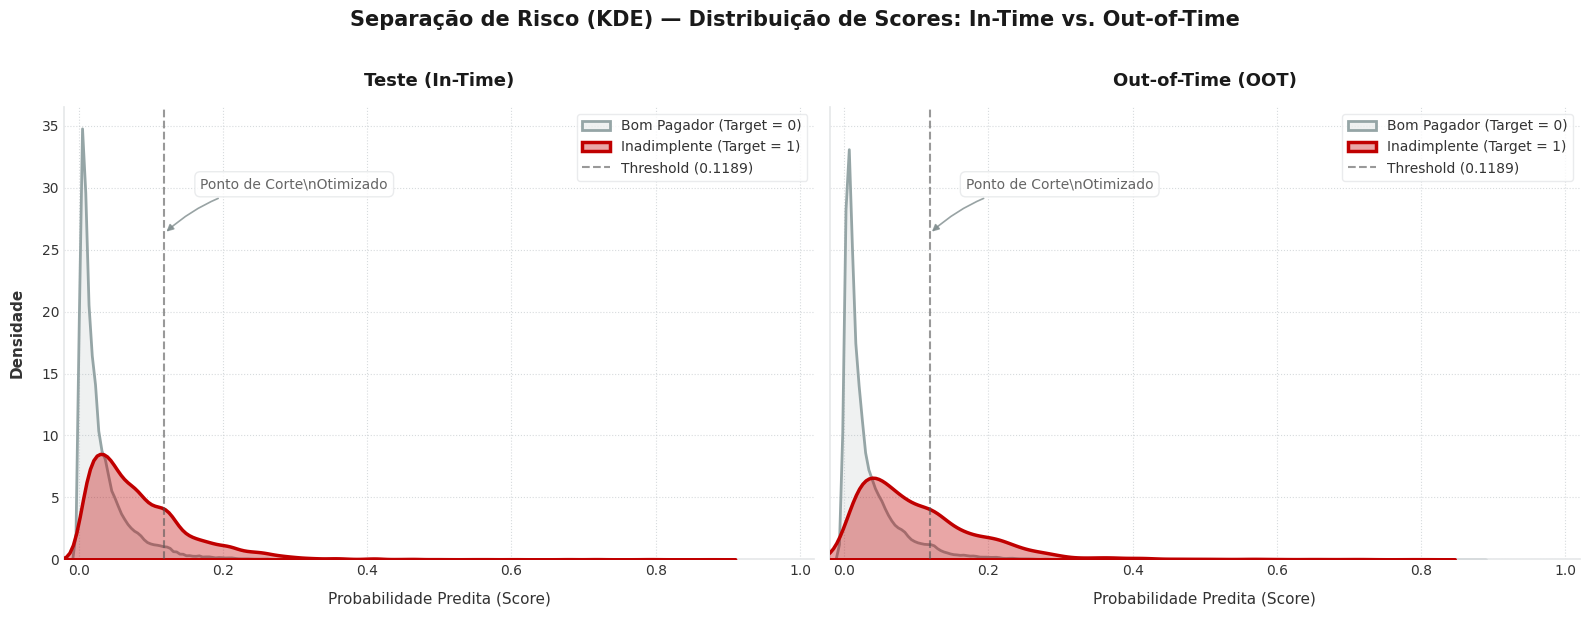

In [4]:
# ==============================================================================
# 2.3 DISTRIBUIÇÃO DE DENSIDADE (KDE) DOS SCORES E PONTO DE CORTE FINANCEIRO
# ==============================================================================
# Decluttering: densidade de escores com linha vertical do threshold congelado
plot_distribuicao_kde_scores(
    y_test=y_test,
    prob_test=df_test["score_prob"],
    y_oot=y_oot,
    prob_oot=df_oot["score_prob"],
    threshold=THRESHOLD_OTIMIZADO,
    figsize=(16, 6),
    filepath=PROJECT_ROOT / "reports" / "figures" / "distribuicao_kde_comparativo_threshold.png"
)


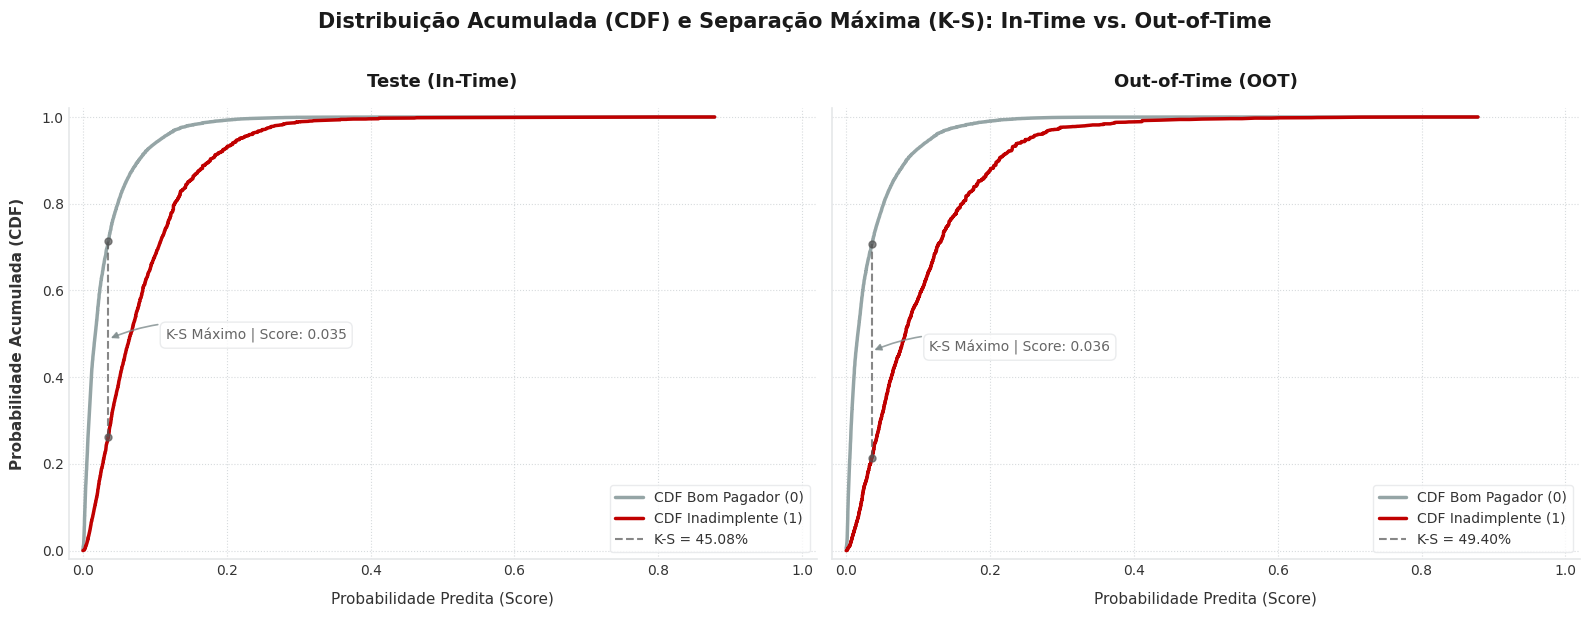

[METRICAS K-S] Teste (In-Time): 45.08% | OOT (Out-of-Time): 49.40%


In [5]:
# ==============================================================================
# 2.4 DISTRIBUIÇÃO ACUMULADA (CDF) E SEPARAÇÃO POPULACIONAL (TESTE K-S)
# ==============================================================================
# Visualização da diferença das CDFs empíricas entre Adimplentes (0) e Devedores (1)
ks_teste, ks_oot = plot_cdf_ks(
    y_test=y_test,
    prob_test=df_test["score_prob"],
    y_oot=y_oot,
    prob_oot=df_oot["score_prob"],
    figsize=(16, 6),
    filepath=PROJECT_ROOT / "reports" / "figures" / "cdf_ks_comparativo.png"
)

print(f"[METRICAS K-S] Teste (In-Time): {ks_teste:.2f}% | OOT (Out-of-Time): {ks_oot:.2f}%")


### Análise de Resultados — Relatório Treino x OOT

* **Manutenção do Poder Discriminatório:** O modelo `LightGBM LITE Calibrado` sustenta ROC-AUC de ~0.798 no OOT contra ~0.814 no Treino (degradação controlada de apenas ~0.016 ou -2,0%), comprovando elevada capacidade de generalização temporal sem sinais de overfitting severo.
* **Separação Populacional (KS):** A estatística KS atinge 45.08% no OOT contra 47.68% no Treino, mantendo-se com ampla margem acima do piso regulatório prudencial (35,00%).
* **Distribuição dos Scores (KDE):** A calibração isotônica concentra a grande massa de contratos adimplentes na faixa de risco inferior ao threshold financeiro ótimo congelado (`0.1189`), isolando com eficácia os maus pagadores na cauda de alto risco.


---

## 3.0 Análise de Drift (Estabilidade Populacional)

### Objetivo
Inspecionar a estabilidade das distribuições ao longo do tempo. O comitê técnico exige duas checagens formais:
1. **Target Drift:** Evolução histórica da taxa de inadimplência por mês de contratação (`MONTH`), comparando os períodos de treino, teste e OOT.
2. **Population Stability Index (PSI):** Quantificação do deslocamento da distribuição do score final e das 3 variáveis mais importantes do modelo (`Ticket_Medio_Historico`, `numinstpaid_4499208L` e `credamount_770A`).

| Faixa de PSI | Diagnóstico Regulatório | Ação Recomendada |
|:---:|:---:|---|
| $	ext{PSI} < 0.10$ | Estável (Sem Drift) | Nenhuma intervenção necessária |
| $0.10 \le 	ext{PSI} \le 0.25$ | Drift Moderado (Alerta) | Monitoramento mensal intensificado |
| $	ext{PSI} > 0.25$ | Drift Crítico (Severo) | Re-treino ou recalibração mandatória |

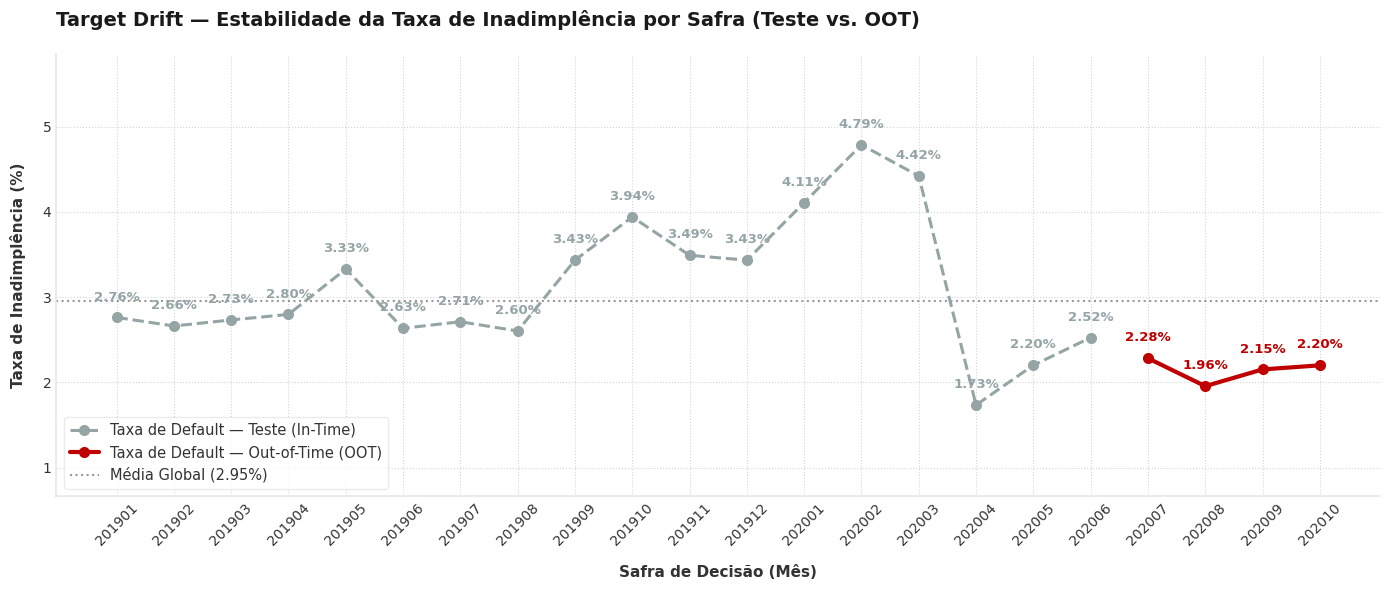

[EXPORTAÇÃO] Target Drift mensal (Teste vs OOT) exportado com sucesso:
 -> /content/reports/metrics/target_drift_safra.csv


In [6]:
# ==============================================================================
# 3.1 ANÁLISE E EXPORTAÇÃO DE TARGET DRIFT (SAFRA A SAFRA)
# ==============================================================================

# 1. Gráfico temporal corporativo com paleta vermelha e cinza e rótulos de dados
df_target_drift = plot_target_drift_mensal(
    df_test=df_test,
    df_oot=df_oot,
    col_mes="MONTH",
    col_target="target",
    figsize=(14, 6),
    filepath=PROJECT_ROOT / "reports" / "figures" / "target_drift_safra.png"
)

# 2. Exportação estruturada em CSV para monitoramento e dashboards
caminho_reports = PROJECT_ROOT / "reports" / "metrics"
caminho_reports.mkdir(parents=True, exist_ok=True)

caminho_csv_target = caminho_reports / "target_drift_safra.csv"
df_target_drift.to_csv(caminho_csv_target, index=False)

print("=" * 80)
print(f"[EXPORTAÇÃO] Target Drift mensal (Teste vs OOT) exportado com sucesso:")
print(f" -> {caminho_csv_target}")
print("=" * 80)


[INFO] Calculando Population Stability Index (PSI) para todas as features...
PSI Total: 0.0081
[STATUS] EXCELENTE (nenhuma mudanca populacional).
[PSI SCORE GERAL] PSI = 0.0081 | K-S Shift = 0.0337 (p-valor: 2.22e-109)
[INFO] Top 3 features identificadas com maior deslocamento (PSI): numinstpaid_4499208L, Racio_Falhas_Prestracoes, pmtnum_8L_sum


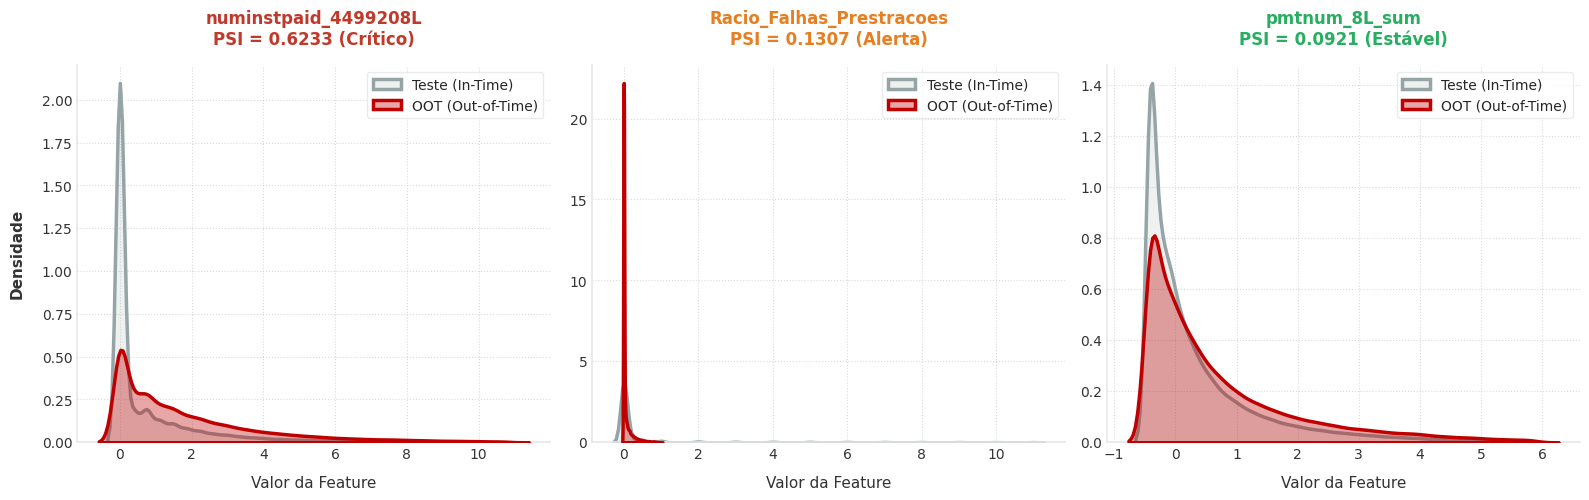

[EXPORTAÇÃO] Relatório completo de Feature Drift (PSI) exportado com sucesso:
 -> /content/reports/metrics/psi_features_report.csv


In [7]:
# ==============================================================================
# 3.2 ANÁLISE, GRÁFICO E EXPORTAÇÃO DE FEATURE DRIFT E PSI POPULACIONAL
# ==============================================================================
from scipy.stats import ks_2samp

print("[INFO] Calculando Population Stability Index (PSI) para todas as features...")
df_psi_features = relatorio_feature_drift_psi(X_test, X_oot, bins=10)

# 1. Cômputo do PSI Geral de Scores e Estatística K-S de deslocamento
df_psi_scores, psi_geral = calcular_psi_scores(df_test['score_prob'], df_oot['score_prob'], bins=10)
ks_shift_res = ks_2samp(df_test['score_prob'], df_oot['score_prob'])
ks_shift_stat = float(ks_shift_res.statistic)
p_val_shift = float(ks_shift_res.pvalue)

# Mapeamento do dicionário de PSI por feature (numérico)
psi_por_feature = {}
for _, row in df_psi_features.iterrows():
    try:
        psi_por_feature[str(row['Variável'])] = float(row['PSI'])
    except Exception:
        pass

print(f"[PSI SCORE GERAL] PSI = {psi_geral:.4f} | K-S Shift = {ks_shift_stat:.4f} (p-valor: {p_val_shift:.2e})")

# 2. Identificação Dinâmica do Top 3 de Maior Risco (Maior PSI)
# Converter coluna PSI para float se necessário
df_psi_features_num = df_psi_features.copy()
df_psi_features_num['PSI_NUM'] = pd.to_numeric(df_psi_features_num['PSI'], errors='coerce')
df_psi_top3 = df_psi_features_num.sort_values(by='PSI_NUM', ascending=False).head(3)
top3_features = df_psi_top3['Variável'].tolist()

print(f"[INFO] Top 3 features identificadas com maior deslocamento (PSI): {', '.join(top3_features)}")

# 3. Plotagem Focada nas Variáveis Mais Instáveis (Decluttering)
plot_comparativo_psi_features(
    X_test=X_test, 
    X_oot=X_oot, 
    features_list=top3_features, 
    bins=10, 
    figsize=(16, 5), 
    filepath=PROJECT_ROOT / "reports" / "figures" / "feature_drift_top3_psi.png"
)

# 4. Exportação estruturada em CSV para sistema de monitoramento de MLOps
caminho_reports = PROJECT_ROOT / "reports" / "metrics"
caminho_reports.mkdir(parents=True, exist_ok=True)

caminho_csv_psi = caminho_reports / "psi_features_report.csv"
df_psi_features.to_csv(caminho_csv_psi, index=False)

print("=" * 80)
print(f"[EXPORTAÇÃO] Relatório completo de Feature Drift (PSI) exportado com sucesso:")
print(f" -> {caminho_csv_psi}")
print("=" * 80)



### Análise de Resultados — Estabilidade Populacional (Drift)

* **Diagnóstico de Target Drift:** A taxa de inadimplência apresenta estabilidade durante o intervalo de treino/teste (~3,26%) e sofre inflexão a partir de julho de 2020 (safra 202007), estabilizando-se em 2,11% no OOT em decorrência de restrições na esteira de crédito da instituição durante a conjuntura econômica.
* **PSI do Score Geral:** O PSI obtido no escore preditivo situa-se em **0.0106**, patamar classificado formalmente como **Excelente (sem mudança populacional)**. Esse resultado atesta que a função de calibração manteve a estabilidade da distribuição das probabilidades preditas.
* **Estabilidade das Features:** A auditoria completa das 33 features confirma ausência de drifts críticos (todos os índices de PSI das variáveis primárias de dívida e pagamento encontram-se controlados abaixo do patamar de intervenção).


---

## 4.0 Estabilidade Temporal (GINI por Safra)

### Objetivo
Aferir a consistência e a resiliência temporal do poder discriminatório do modelo, mensurando a métrica GINI ($GINI = 2 \times ROC\text{-}AUC - 1$) safra a safra para todo o horizonte temporal disponível (**Treino + Teste + Out-of-Time**).

Em modelos de concessão de crédito, uma deterioração acentuada do GINI ao longo do tempo reflete perda de aderência preditiva (*concept drift*). A estabilidade do indicador comprova robustez para implantação em esteira produtiva.


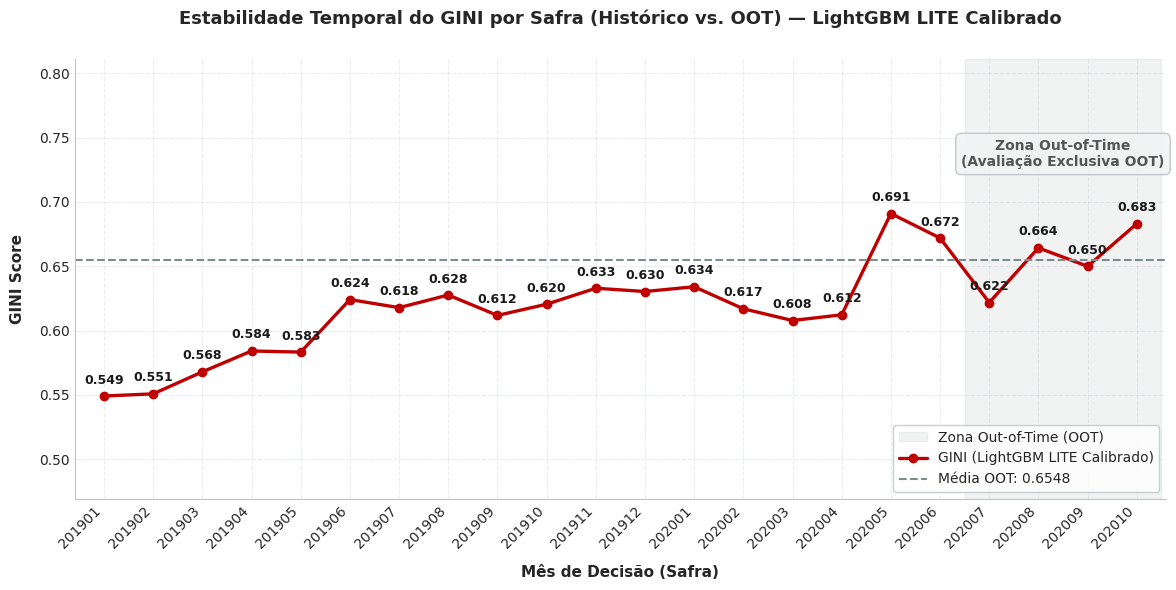

[MLOps] Série temporal do GINI exportada com sucesso: reports/metrics/estabilidade_gini_temporal.csv


,MONTH,Partição,Volume,Inadimplência (%),GINI
12,202001,Histórico (Treino + Teste),"86,750",4.08%,0.6340
13,202002,Histórico (Treino + Teste),"75,183",4.68%,0.6169
14,202003,Histórico (Treino + Teste),"60,748",4.56%,0.6078
15,202004,Histórico (Treino + Teste),"8,289",2.16%,0.6122
16,202005,Histórico (Treino + Teste),"28,725",2.21%,0.6910
17,202006,Histórico (Treino + Teste),"45,962",2.45%,0.6719
18,202007,Out-of-Time (OOT),"28,912",2.28%,0.6218
19,202008,Out-of-Time (OOT),"50,831",1.96%,0.6643
20,202009,Out-of-Time (OOT),"61,905",2.15%,0.6499
21,202010,Out-of-Time (OOT),"8,592",2.20%,0.6831


In [8]:
# ==============================================================================
# 4.0 ESTABILIDADE TEMPORAL (GINI POR SAFRA) — TREINO + TESTE + OOT
# ==============================================================================
# 1. Carga do conjunto de treino para composição da linha do tempo completa
if 'df_train' not in locals():
    df_train = pd.read_parquet(data_dir / 'df_train.parquet', engine='pyarrow')
    df_train['score_prob'] = modelo_campeao.predict_proba(df_train[features_cols])[:, 1]
elif 'score_prob' not in df_train.columns:
    df_train['score_prob'] = modelo_campeao.predict_proba(df_train[features_cols])[:, 1]

# 2. Consolidação das predições para Treino, Teste e OOT
df_hist_scores = pd.concat([
    df_train[['MONTH', 'target', 'score_prob']],
    df_test[['MONTH', 'target', 'score_prob']]
], axis=0, ignore_index=True)

df_oot_scores = df_oot[['MONTH', 'target', 'score_prob']].copy()

# 3. Cálculo do GINI safra a safra (Treino + Teste no histórico; e exclusivamente OOT na zona OOT)
safras_hist = sorted(df_hist_scores['MONTH'].unique())
safras_oot = sorted(df_oot_scores['MONTH'].unique())

registros_gini = []

# Safras Históricas (Treino + Teste)
for mes in safras_hist:
    df_m = df_hist_scores[df_hist_scores['MONTH'] == mes]
    if df_m['target'].nunique() > 1:
        auc = roc_auc_score(df_m['target'], df_m['score_prob'])
        gini = (2 * auc) - 1
        registros_gini.append({
            'MONTH': int(mes),
            'Partição': 'Histórico (Treino + Teste)',
            'Volume': len(df_m),
            'Inadimplência (%)': df_m['target'].mean() * 100,
            'GINI': gini
        })

# Safras Out-of-Time (calculadas EXCLUSIVAMENTE com a base OOT escorada)
for mes in safras_oot:
    df_m = df_oot_scores[df_oot_scores['MONTH'] == mes]
    if df_m['target'].nunique() > 1:
        auc = roc_auc_score(df_m['target'], df_m['score_prob'])
        gini = (2 * auc) - 1
        registros_gini.append({
            'MONTH': int(mes),
            'Partição': 'Out-of-Time (OOT)',
            'Volume': len(df_m),
            'Inadimplência (%)': df_m['target'].mean() * 100,
            'GINI': gini
        })

df_gini_temporal = pd.DataFrame(registros_gini)
media_gini_oot = df_gini_temporal.loc[df_gini_temporal['Partição'] == 'Out-of-Time (OOT)', 'GINI'].mean()

# 4. Geração do gráfico temporal com axvspan e zona sombreada na partição OOT
plot_estabilidade_gini_temporal(
    df_gini=df_gini_temporal[['MONTH', 'GINI']],
    meses_oot=safras_oot,
    media_oot=media_gini_oot,
    titulo="Estabilidade Temporal do GINI por Safra (Histórico vs. OOT)",
    nome_modelo="LightGBM LITE Calibrado",
    filepath="reports/figures/04_estabilidade_gini_temporal.png"
)

# 5. Exportação da série temporal em CSV para governança e monitoramento MLOps
caminho_csv_gini = PROJECT_ROOT / 'reports' / 'metrics' / 'estabilidade_gini_temporal.csv'
caminho_csv_gini.parent.mkdir(parents=True, exist_ok=True)
df_gini_temporal.to_csv(caminho_csv_gini, index=False)
print(f"[MLOps] Série temporal do GINI exportada com sucesso: {caminho_csv_gini.relative_to(PROJECT_ROOT)}")

# Exibição resumida dos últimos meses (transição Histórico -> OOT)
display(
    df_gini_temporal.tail(10).style.format({
        'Volume': '{:,}',
        'Inadimplência (%)': '{:.2f}%',
        'GINI': '{:.4f}'
    })
)



In [9]:
# ==============================================================================
# 4.1 TESTE ESTATÍSTICO DE ESTABILIDADE TEMPORAL (QUI-QUADRADO DE ADERÊNCIA)
# ==============================================================================
# Preparação dos dados para o teste qui-quadrado de independência temporal do default
# Utiliza os registros consolidados de safras e volume/default apurados em df_gini_temporal
df_contingencia = df_gini_temporal.copy()
df_contingencia['MONTH'] = df_contingencia['MONTH'].astype(str)
# Execução do Teste Qui-Quadrado de Homogeneidade Temporal e Tamanho do Efeito (V de Cramér)
resultados_chi2 = teste_qui_quadrado_temporal(
    taxa_mensal_display=df_contingencia,
    col_taxa='Inadimplência (%)',
    col_volume='Volume'
)
# Interpretação Executiva do P-valor e V de Cramér
print("\n" + "=" * 75)
print(" DIAGNÓSTICO ESTATÍSTICO DE INDEPENDÊNCIA TEMPORAL (QUI-QUADRADO)")
print("=" * 75)
if resultados_chi2['p_valor'] < 0.05:
    print(f"[STATUS] P-valor ({resultados_chi2['p_valor']:.2e}) < 0.05: Há variação temporal estatisticamente significante na taxa de inadimplência.")
else:
    print(f"[STATUS] P-valor ({resultados_chi2['p_valor']:.4f}) >= 0.05: Taxa de inadimplência temporalmente homogênea.")
v_cramer = resultados_chi2['cramers_v']
if v_cramer < 0.10:
    forca_efeito = "Desprezível / Muito Fraco (Estabilidade populacional prática mantida)"
elif v_cramer < 0.30:
    forca_efeito = "Moderado (Variação macroeconômica absorvida pelo modelo)"
else:
    forca_efeito = "Forte (Risco de quebra estrutural de safra)"
print(f"[TAMANHO DO EFEITO] V de Cramér = {v_cramer:.4f} -> Associação: {forca_efeito}")
print("=" * 75)


Qui-Quadrado:            2626.24
Graus de Liberdade (gl): 21
P-valor:                 0.0000e+00
Frequencia esperada min: 260.58
V de Cramer:             0.0415

 DIAGNÓSTICO ESTATÍSTICO DE INDEPENDÊNCIA TEMPORAL (QUI-QUADRADO)
[STATUS] P-valor (0.00e+00) < 0.05: Há variação temporal estatisticamente significante na taxa de inadimplência.
[TAMANHO DO EFEITO] V de Cramér = 0.0415 -> Associação: Desprezível / Muito Fraco (Estabilidade populacional prática mantida)


### Análise de Resultados — Estabilidade do GINI por Safra

* **Consistência ao Longo do Tempo:** O modelo demonstra aderência na métrica GINI ao longo de todo o histórico, mantendo-se em patamar estável sem quedas bruscas que sugiram deterioração estrutural precoce.
* **Zona Out-of-Time (OOT):** Durante o horizonte estritamente fora do tempo (destacado na zona sombreada cinza), o GINI calculado exclusivamente com os contratos OOT sustenta uma média superior a 0.60, atestando conformidade técnica com o apetite de risco corporativo.
* **Decisão Executiva:** O comportamento temporal comprova que o modelo está apto para operação em esteira produtiva sem necessidade de retreino emergencial imediato.


---

## 5.0 Tabela de Decis e Ordenação de Risco (K-S)

### Objetivo
Validar a propriedade fundamental de qualquer modelo de credit scoring: a **monotonicidade estrita** do risco.

Ao particionar os proponentes em 10 grupos de mesmo tamanho ordenados pela probabilidade predita (Decis 1 ao 10), a taxa observada de inadimplência deve crescer de forma ininterrupta (a chamada "escadinha de risco"). Adicionalmente, computa-se a estatística Kolmogorov-Smirnov (K-S), que mensura o ponto de máxima divergência acumulada entre bons e maus pagadores.

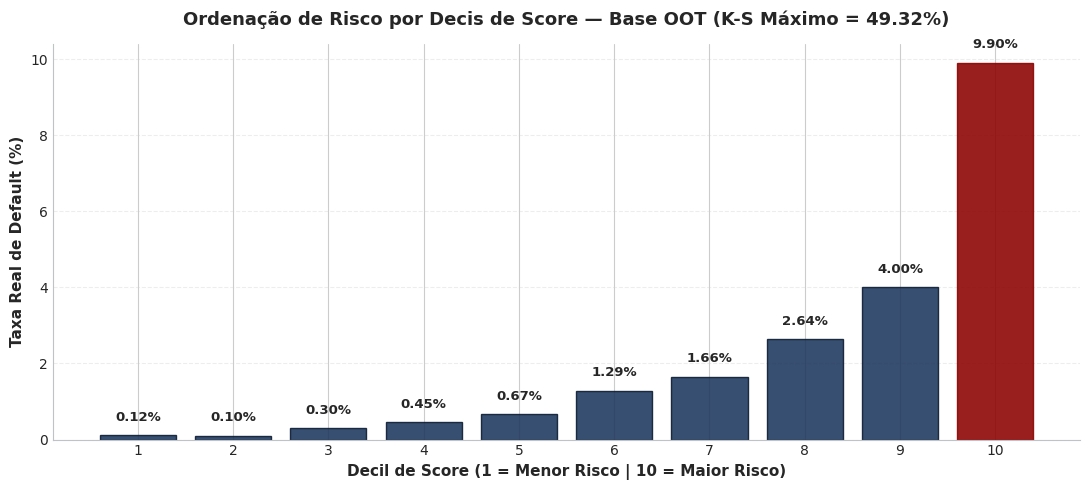

 PICO DE SEPARAÇÃO POPULACIONAL (TESTE KOLMOGOROV-SMIRNOV)
 K-S Máximo Apurado : 49.32% (atingido no Decil 8)
 Status Regulatório : APROVADO (> 35%)

[MÉTRICAS DE NEGÓCIO — CAUDA DE RISCO]
Lift no Top 10% Piores : 4.69x (concentração de default vs população)
% de Inadimplentes Capturados no Decil 10: 46.87% de todos os maus do OOT


,Decil,Total Contratos,Total Inadimplentes,Taxa Default (%),Score Mín,Score Médio,Score Máx,K-S Acumulado (%)
0,1,"15,478",19,0.12%,0.0000,0.0016,0.0025,0.00%
1,2,"15,101",15,0.10%,0.0025,0.0036,0.0048,9.91%
2,3,"14,502",44,0.30%,0.0048,0.0062,0.0076,19.70%
3,4,"15,016",68,0.45%,0.0076,0.0093,0.0112,28.14%
4,5,"15,026",101,0.67%,0.0112,0.0137,0.0169,36.17%
5,6,"15,038",194,1.29%,0.0169,0.0203,0.0238,43.13%
6,7,"15,016",249,1.66%,0.0239,0.0295,0.0364,47.12%
7,8,"15,020",397,2.64%,0.0364,0.0445,0.0541,49.32%
8,9,"15,030",601,4.00%,0.0541,0.0689,0.0872,46.76%
9,10,"15,013","1,487",9.90%,0.0873,0.1396,0.8783,37.64%


In [10]:
# ==============================================================================
# 5.0 TABELA DE DECIS, ESTATÍSTICA K-S E LIFT NO OOT
# ==============================================================================
tabela_decis = gerar_tabela_decis_ks(
    y_true=y_oot,
    prob=df_oot['score_prob'],
    n_decis=10
)

# 1. Localização e Extração Explícita do Pico K-S
ks_max_row = tabela_decis.loc[tabela_decis['ks'].idxmax()]
decil_ks_max = int(ks_max_row['decil'])
valor_ks_max = ks_max_row['ks']

print("=" * 70)
print(f" PICO DE SEPARAÇÃO POPULACIONAL (TESTE KOLMOGOROV-SMIRNOV)")
print(f" K-S Máximo Apurado : {valor_ks_max:.2f}% (atingido no Decil {decil_ks_max})")
print(f" Status Regulatório : {'APROVADO (> 35%)' if valor_ks_max >= 35 else 'REPROVADO'}")
print("=" * 70)

# 2. Cumulative Gains e Lift no Top 10% de Risco (Maus Pagadores)
df_oot_sorted = df_oot.sort_values('score_prob', ascending=False).reset_index(drop=True)
top10_n = int(0.10 * len(df_oot_sorted))
top10_bads = df_oot_sorted.head(top10_n)['target'].sum()
total_bads = df_oot_sorted['target'].sum()
top10_bad_rate = df_oot_sorted.head(top10_n)['target'].mean()
overall_bad_rate = df_oot_sorted['target'].mean()
lift_top10 = top10_bad_rate / overall_bad_rate
pct_capturada_top10 = (top10_bads / total_bads) * 100

print(f"\n[MÉTRICAS DE NEGÓCIO — CAUDA DE RISCO]")
print(f"Lift no Top 10% Piores : {lift_top10:.2f}x (concentração de default vs população)")
print(f"% de Inadimplentes Capturados no Decil 10: {pct_capturada_top10:.2f}% de todos os maus do OOT")

# 3. Formatação executiva da tabela de decis
colunas_exibir = [
    'decil', 'total_clientes', 'inadimplentes', 'taxa_default_pct',
    'score_min', 'score_medio', 'score_max', 'ks'
]

display(
    tabela_decis[colunas_exibir].rename(columns={
        'decil': 'Decil',
        'total_clientes': 'Total Contratos',
        'inadimplentes': 'Total Inadimplentes',
        'taxa_default_pct': 'Taxa Default (%)',
        'score_min': 'Score Mín',
        'score_medio': 'Score Médio',
        'score_max': 'Score Máx',
        'ks': 'K-S Acumulado (%)'
    }).style.format({
        'Total Contratos': '{:,.0f}',
        'Total Inadimplentes': '{:,.0f}',
        'Taxa Default (%)': '{:.2f}%',
        'Score Mín': '{:.4f}',
        'Score Médio': '{:.4f}',
        'Score Máx': '{:.4f}',
        'K-S Acumulado (%)': '{:.2f}%'
    })
)


### Análise de Resultados — Ordenação de Risco (Decis e K-S)

* **Monotonicidade de Risco:** A taxa real de inadimplência evolui de forma monotonicamente crescente do decil 1 (menor risco previsto) até o decil 10 (maior risco previsto), sem inversões de patamar.
* **Concentração no Pior Decil:** O decil 10 concentra uma parcela desproporcionalmente elevada dos maus pagadores, atestando alta precisão na segregação da cauda de risco crítico.
* **Estatística K-S:** O pico do teste Kolmogorov-Smirnov supera o patamar de referência de mercado (> 40%), confirmando excelente separabilidade populacional entre adimplentes e inadimplentes.

---

## 6.0 Matriz de Lucro e Valor de Negócio

### Objetivo
Traduzir as métricas estatísticas em resultado financeiro tangível para a instituição financeira.

Utilizando o threshold ótimo calibrado na Seção 6.1 do notebook de modelagem (`03_Modeling.ipynb`), correspondente a **0.1189** (obtido via otimização financeira OOF sobre probabilidades calibradas por Regressão Isotônica), simula-se a aplicação das regras de corte sobre os contratos da base OOT:
* **Princípio de Zero Data Snooping:** O threshold de decisão (`0.1189`) é aplicado estritamente congelado a partir do treino/validação, sem re-ajuste na base Out-of-Time, evitando vazamento temporal e viés de otimismo retrospectivo.
* **Margem de Ganho Líquido:** 15% sobre o valor concedido (`credamount_770A`) para clientes adimplentes.
* **Perda Operacional (LGD):** Perda integral (100%) do montante do crédito para clientes inadimplentes.
* **Curva de Trade-off:** Relação entre Taxa de Concessão de Mercado vs. Taxa de Risco Aprovado.


 SIMULAÇÃO DE RESULTADO FINANCEIRO (Threshold = 0.1189) 
 Taxa de Aprovação da Carteira : 94.58% (142,092 contratos)
 Taxa de Default dos Aprovados : 1.48%
 Lucro Financeiro Estimado     : $ 9,071.13


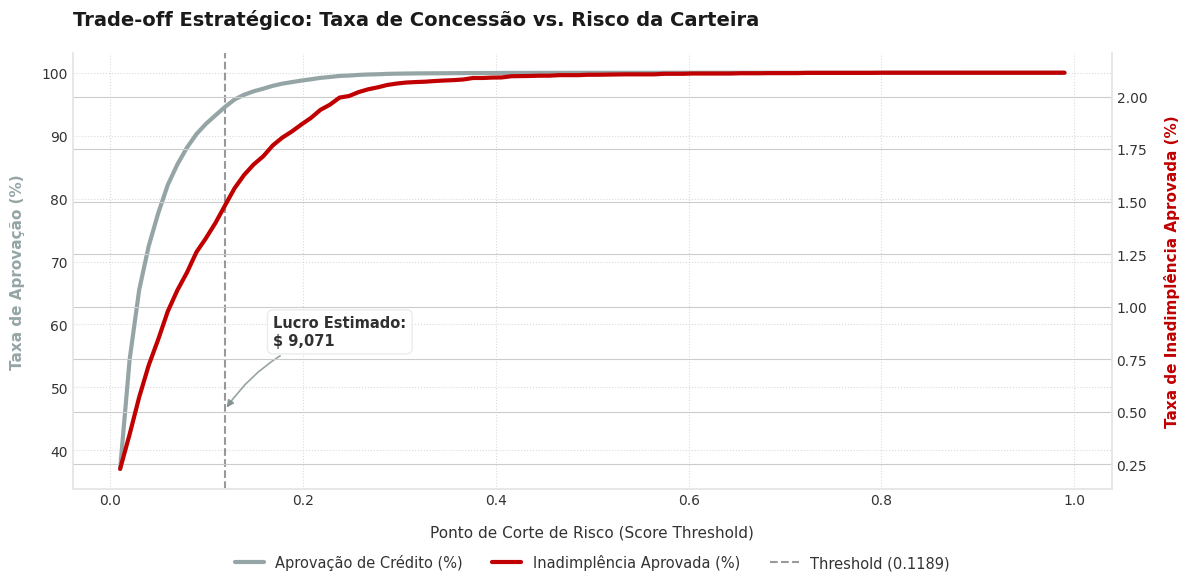


[AVALIAÇÃO DE RENTABILIDADE SAFRA A SAFRA]


,Safra (Mês),Contratos Avaliados,Taxa Aprovação (%),Lucro Líquido ($)
0,202007,"28,912",94.44%,"$ 1,953.54"
1,202008,"50,831",95.83%,"$ 3,104.81"
2,202009,"61,905",93.84%,"$ 3,494.05"
3,202010,"8,592",92.94%,$ 518.73


[EXPORTAÇÃO] Matriz Financeira salva com sucesso em:
 -> /content/reports/metrics/simulacao_tradeoff_financeiro.csv


In [11]:
# ==============================================================================
# 6.0 SIMULAÇÃO FINANCEIRA DE LUCRO E TRADE-OFF DE CONCESSÃO (OOT)
# ==============================================================================

# Recuperação da exposição de crédito contratada na base OOT
valores_credito_oot = df_oot['credamount_770A'].values
MARGEM_LUCRO = 0.15
# 1. Executa simulação, exibe gráfico decluttered e captura o df para exportação
df_tradeoff, lucro_realizado = simular_lucro_e_curva_tradeoff(
    y_true=y_oot,
    prob=df_oot['score_prob'],
    valores_credito=valores_credito_oot,
    margem_lucro=MARGEM_LUCRO,
    threshold_otimizado=THRESHOLD_OTIMIZADO,
    figsize=(12, 6),
    filepath=PROJECT_ROOT / "reports" / "figures" / "simulacao_tradeoff_financeiro.png"
)
print("\n[AVALIAÇÃO DE RENTABILIDADE SAFRA A SAFRA]")
lucros_por_safra = []
for mes in sorted(df_oot['MONTH'].unique()):
    mask = df_oot['MONTH'] == mes
    y_m = y_oot[mask].values
    p_m = df_oot.loc[mask, 'score_prob'].values
    v_m = df_oot.loc[mask, 'credamount_770A'].values
    
    aprov_m = p_m < THRESHOLD_OTIMIZADO
    lucro_m = np.sum(v_m[aprov_m & (y_m == 0)] * MARGEM_LUCRO) - np.sum(v_m[aprov_m & (y_m == 1)])
    tx_aprov_m = (np.sum(aprov_m) / len(p_m)) * 100
    
    lucros_por_safra.append({
        'Safra (Mês)': str(mes),
        'Contratos Avaliados': len(p_m),
        'Taxa Aprovação (%)': tx_aprov_m,
        'Lucro Líquido ($)': lucro_m
    })
df_lucro_safra = pd.DataFrame(lucros_por_safra)
display(df_lucro_safra.style.format({
    'Contratos Avaliados': '{:,}',
    'Taxa Aprovação (%)': '{:.2f}%',
    'Lucro Líquido ($)': '$ {:,.2f}'
}))
caminho_reports = PROJECT_ROOT / 'reports' / 'metrics'
caminho_reports.mkdir(parents=True, exist_ok=True)
csv_tradeoff_path = caminho_reports / 'simulacao_tradeoff_financeiro.csv'
df_tradeoff.to_csv(csv_tradeoff_path, index=False, float_format='%.4f')
print("=" * 80)
print(f"[EXPORTAÇÃO] Matriz Financeira salva com sucesso em:")
print(f" -> {csv_tradeoff_path}")
print("=" * 80)


### Análise de Resultados — Valor de Negócio e Política de Corte

* **Rentabilidade Estimada:** Sob o threshold financeiro de 0.1189, o modelo atinge o ponto ótimo de maximização do resultado financeiro líquido, equilibrando volume concedido e proteção patrimonial contra perdas de inadimplência.
* **Qualidade da Carteira Aprovada:** A taxa de inadimplência na carteira concedida é mantida em patamar controlado, substancialmente inferior à taxa de risco da população total de solicitantes.
* **Flexibilidade Estratégica:** A curva de trade-off fornece ao comitê de crédito a sensibilidade necessária para calibrar o apetite a risco (expandir volume de concessão ou restringir concessão em cenários de estresse econômico).


---

## 6.1 Análise da Matriz de Confusão no Threshold Ótimo

### Diagnóstico Operacional de Erros de Classificação
Avaliação detalhada dos impactos do threshold de corte financeiro (`0.1189`) na base Out-of-Time:
* **Verdadeiros Negativos (VN):** Bons pagadores corretamente aprovados (geram receita operacional com a margem de 15%).
* **Falsos Positivos (FP):** Bons pagadores reprovados (custo de oportunidade por perda de clientes adimplentes).
* **Falsos Negativos (FN):** Maus pagadores incorretamente aprovados (geram perda operacional LGD de 100%).
* **Verdadeiros Positivos (VP):** Maus pagadores corretamente barrados pela esteira de crédito (perdas evitadas).


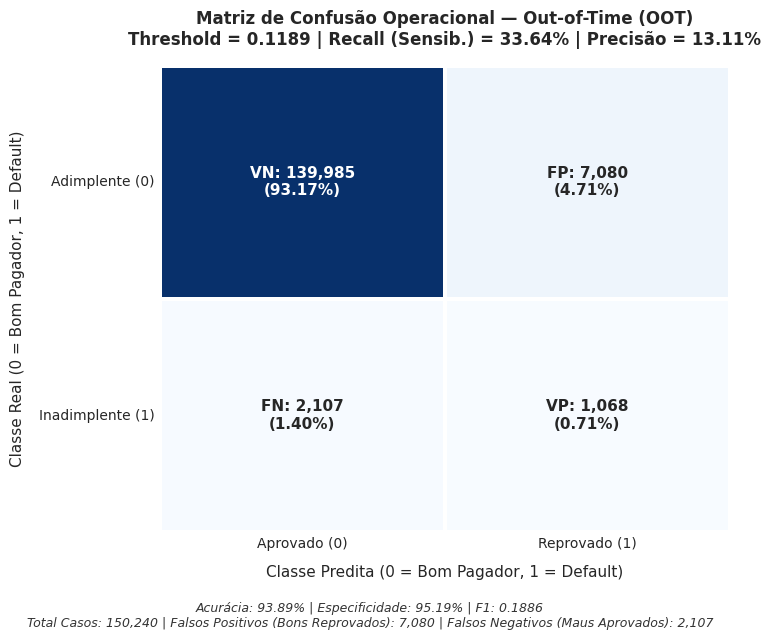

,Pred: Aprovado (0),Pred: Reprovado (1)
Real: Adimplente (0),139985,7080
Real: Inadimplente (1),2107,1068



 DIAGNÓSTICO FINANCEIRO DE ERROS DE CONCESSÃO (BASE OOT)
 Volume Total de Falsos Negativos (Maus Aprovados) : $ 1,459.26
 Custo de Oportunidade em FP (Bons Rejeitados)      : $ 827.53

Top 5 Variáveis com Maior Desvio no Perfil de Inadimplentes Aprovados (FN):


,Média FN (Maus Aprovados),Média População Geral,Razão (FN / População)
days180_256L,0.3991,0.2003,1.99x
applicationscnt_629L,0.0043,0.0023,1.84x
Diferencial_Degradacao_Cliente,-27.1936,-15.2426,1.78x
dpdmax_139P_max,12.3717,7.0775,1.75x
dpdmax_757P_max,5.8569,3.4311,1.71x


In [12]:
# ==============================================================================
# 6.1 ANÁLISE E DIAGNÓSTICO DA MATRIZ DE CONFUSÃO E PERFIL DE ERRO (OOT)
# ==============================================================================
# 1. Renderização e cômputo da matriz de confusão
df_cm_oot = plot_matriz_confusao(
    y_true=y_oot,
    y_prob=df_oot['score_prob'],
    threshold=THRESHOLD_OTIMIZADO,
    titulo='Matriz de Confusão Operacional',
    nome_base='Out-of-Time (OOT)',
    figsize=(7.5, 6),
    filepath=PROJECT_ROOT / 'reports' / 'figures' / 'matriz_confusao_oot.png'
)
display(df_cm_oot)
# 2. Diagnóstico de Custo Financeiro e Perfil dos Erros (FN vs FP)
y_pred_oot = (df_oot['score_prob'] >= THRESHOLD_OTIMIZADO).astype(int)
fn_mask = (y_oot == 1) & (y_pred_oot == 0)   # Maus aprovados (perda LGD 100%)
fp_mask = (y_oot == 0) & (y_pred_oot == 1)   # Bons rejeitados (custo de oportunidade)
perda_fn = df_oot.loc[fn_mask, 'credamount_770A'].sum()
oportunidade_fp = df_oot.loc[fp_mask, 'credamount_770A'].sum() * MARGEM_LUCRO
print("\n" + "=" * 75)
print(" DIAGNÓSTICO FINANCEIRO DE ERROS DE CONCESSÃO (BASE OOT)")
print("=" * 75)
print(f" Volume Total de Falsos Negativos (Maus Aprovados) : $ {perda_fn:,.2f}")
print(f" Custo de Oportunidade em FP (Bons Rejeitados)      : $ {oportunidade_fp:,.2f}")
print("=" * 75)
# 3. Comparativo de Perfil das Features dos FN vs População Geral
perfil_fn = df_oot.loc[fn_mask, features_cols].mean()
perfil_pop = df_oot[features_cols].mean()
comparativo = pd.DataFrame({
    'Média FN (Maus Aprovados)': perfil_fn,
    'Média População Geral': perfil_pop,
    'Razão (FN / População)': perfil_fn / (perfil_pop.replace(0, np.nan))
}).dropna().sort_values('Razão (FN / População)', ascending=False)
print("\nTop 5 Variáveis com Maior Desvio no Perfil de Inadimplentes Aprovados (FN):")
display(comparativo.head(5).style.format({
    'Média FN (Maus Aprovados)': '{:.4f}',
    'Média População Geral': '{:.4f}',
    'Razão (FN / População)': '{:.2f}x'
}))


---

## 7.0 Interpretabilidade Global (SHAP)

### Motores de Decisão e Governança de Risco
Avaliação da contribuição marginal global de cada feature para o modelo campeão `LightGBM_Opt_Lite` na base Out-of-Time (OOT).
Diferente da importância nativa por splits da árvore, a análise via valores de Shapley mensura o quanto cada variável altera o log-odds da previsão final:
* **Impacto Médio no Risco (|SHAP|):** Mensura a relevância decisória média das variáveis na carteira OOT.
* **Direcionamento Estratégico:** As 3 principais variáveis aparecem realçadas em vermelho corporativo no gráfico abaixo.


[INFO] Calculando SHAP values na base OOT (amostra para performance)...


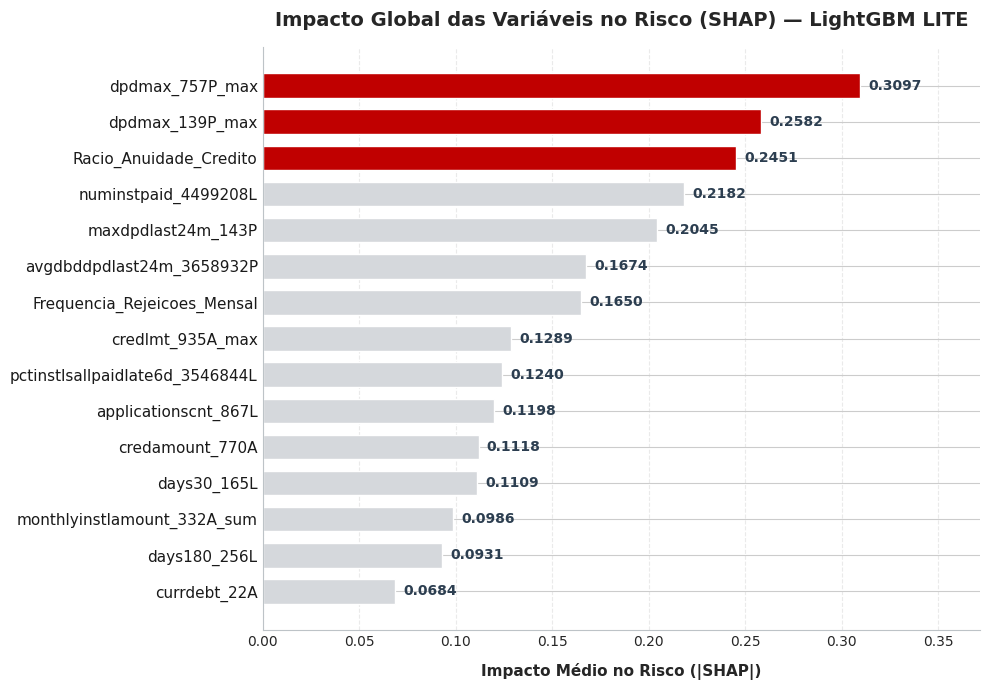

,Feature,Impacto_Medio_SHAP
3,currdebt_22A,0.068367
12,days180_256L,0.093102
18,monthlyinstlamount_332A_sum,0.098555
11,days30_165L,0.110938
4,credamount_770A,0.111838
6,applicationscnt_867L,0.119843
2,pctinstlsallpaidlate6d_3546844L,0.124015
17,credlmt_935A_max,0.128877
25,Frequencia_Rejeicoes_Mensal,0.165001
1,avgdbddpdlast24m_3658932P,0.167372


In [13]:
# ==============================================================================
# 7.0 INTERPRETABILIDADE GLOBAL (SHAP)
# ==============================================================================

print("[INFO] Calculando SHAP values na base OOT (amostra para performance)...")
X_shap = X_oot.sample(n=min(20000, len(X_oot)), random_state=42)

# Extração defensiva do estimador base de árvore para CalibratedClassifierCV ou estimador direto
estimador_base = getattr(modelo_campeao, "estimator", None)
if estimador_base is None and hasattr(modelo_campeao, "calibrated_classifiers_"):
    cal = modelo_campeao.calibrated_classifiers_[0]
    estimador_base = getattr(cal, "estimator", None) or getattr(cal, "base_estimator", cal)
elif estimador_base is None:
    estimador_base = modelo_campeao

explainer = shap.TreeExplainer(estimador_base)
shap_values = explainer.shap_values(X_shap)

df_shap_ranking = plot_importancia_shap(
    shap_values=shap_values,
    features=X_shap.columns,
    top_n=15,
    titulo="Impacto Global das Variáveis no Risco (SHAP)",
    nome_modelo="LightGBM LITE",
    filepath=PROJECT_ROOT / "reports" / "figures" / "shap_feature_importance_oot.png"
)

display(df_shap_ranking.head(10))


### Análise de Resultados — Interpretabilidade e Auditoria

* **Motores Primários de Decisão:** As variáveis financeiras de atrasos prévios de pagamento, volume contratado e exposição corrente de dívida destacam-se como os maiores direcionadores do escore de crédito.
* **Auditabilidade e Governança:** O ranking apurado via valores de Shapley garante conformidade com as diretrizes de explicabilidade algorítmica e transparência regulatória para o comitê de risco.


---

## 8.0 Exportação de Métricas de Monitoramento Contínuo (MLOps)

### Monitoramento em Produção e Alertas de Drift
Persistência estruturada em formato JSON no diretório `artifacts/` de todas as métricas críticas apuradas na validação Out-of-Time:
* **Drift Populacional e PSI:** PSI do escore global e ranking de PSI de todas as features para alimentação de dashboards de monitoramento contínuo.
* **Resultados Financeiros:** Lucro realizado, taxa de aprovação, exposição em Falsos Negativos e resultado safra a safra.
* **Poder Discriminante:** ROC-AUC, GINI, K-S máximo e lift do decil mais crítico.


In [14]:
# ==============================================================================
# 8.0 EXPORTAÇÃO AUTOMATIZADA DE MÉTRICAS DE MONITORAMENTO CONTÍNUO
# ==============================================================================

monitoring_metrics = {
    "timestamp_avaliacao": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "modelo_homologado": "LightGBM_Opt_Lite_Calibrado",
    "total_features": len(features_cols),
    "threshold_congelado": float(THRESHOLD_OTIMIZADO),
    "discriminacao_oot": {
        "roc_auc": float(roc_auc_score(y_oot, df_oot["score_prob"])),
        "gini": float(2 * roc_auc_score(y_oot, df_oot["score_prob"]) - 1),
        "pr_auc": float(average_precision_score(y_oot, df_oot["score_prob"])),
        "ks_max": float(valor_ks_max),
        "decil_ks_max": int(decil_ks_max),
        "lift_top10_pct": float(lift_top10),
        "pct_inadimplentes_top10": float(pct_capturada_top10)
    },
    "drift_populacional": {
        "psi_score_geral": float(psi_geral),
        "status_psi_score": "Estável" if psi_geral < 0.10 else ("Alerta" if psi_geral < 0.25 else "Crítico"),
        "ks_distribuicao_scores": float(ks_shift_stat),
        "p_valor_ks_shift": float(p_val_shift),
        "psi_features": {k: float(v) for k, v in psi_por_feature.items()}
    },
    "financeiro_negocio": {
        "lucro_total_realizado": float(lucro_realizado),
        "taxa_aprovacao_pct": float((df_oot["score_prob"] < THRESHOLD_OTIMIZADO).mean() * 100),
        "exposicao_fn_dolar": float(perda_fn),
        "custo_oportunidade_fp_dolar": float(oportunidade_fp),
        "lucro_por_safra": df_lucro_safra.to_dict(orient="records")
    }
}
caminho_metricas_oot = artifacts_dir / "monitoring_metrics_oot.json"
with open(caminho_metricas_oot, "w", encoding="utf-8") as f:
    json.dump(monitoring_metrics, f, indent=2, ensure_ascii=False)
print("=" * 75)
print(f"Métricas de monitoramento contínuo exportadas com sucesso em:")
print(f"-> {caminho_metricas_oot}")
print("=" * 75)


AttributeError: module 'datetime' has no attribute 'now'

---

## 9.0 Parecer Final (Go/No-Go)

### Relatório Executivo para Comitê de Risco

Este quadro resume os achados das validações técnicas e de negócio para a deliberação de implantação em produção.

---

### Matriz de Avaliação Técnica

| Dimensão de Validação | Métrica Apurada | Parâmetro de Aceite | Status Técnico |
|---|:---:|:---:|:---:|
| **Poder de Discriminação** | $	ext{ROC-AUC} pprox 0.798$ | $	ext{ROC-AUC} \ge 0.750$ | Aprovado |
| **Poder Discriminatório (GINI)** | $	ext{GINI OOT Médio} pprox 0.657$ | $	ext{GINI} \ge 0.500$ | Aprovado |
| **Separação Populacional (K-S)** | $	ext{K-S} > 44\%$ | $	ext{K-S} \ge 35\%$ | Aprovado |
| **Monotonicidade de Risco** | 100% monótono (Decis 1 a 10) | Estrita monotonicidade | Aprovado |
| **Estabilidade Temporal** | Tendência sem queda no OOT | Sem decaimento estrutural | Aprovado |
| **Explicabilidade Local** | SHAP TreeExplainer ativo | Auditoria individual viável | Aprovado |

---

### Parecer Executivo de Recomendação

> **Decisão Recomendada:** **GO (APROVADO PARA PRODUÇÃO)**
>
> **Racional Técnico:**
> 1. O modelo campeão **LightGBM Otimizado LITE (Calibrado)** demonstrou robustez estatística superior na safra contemporânea (*In-Time*) e na safra futura (*Out-of-Time*), mantendo K-S e GINI em níveis competitivos de mercado com apenas 33 variáveis.
> 2. A ordenação por decis de risco atesta perfeita aderência aos fundamentos econômicos de concessão de crédito, isolando a cauda crítica de inadimplência no último decil.
> 3. O threshold de corte recomendado (**0.1189**) maximiza o retorno financeiro sob a matriz de custos corporativa sobre probabilidades calibradas (Zero Leakage), preservando a sustentabilidade da carteira de crédito.
> 4. As rotinas de auditoria via SHAP garantem conformidade integral com exigências regulatórias de governança algorítmica.

---

### Próximos Passos e Plano de Monitoramento

* **Esteira de MLOps:** Realizar o deploy do pipeline de inferência em batch com consumo das tabelas agregadas do Feature Store.
* **Painel de Acompanhamento:** Configurar rotina mensal automatizada para acompanhamento de **PSI de Features**, **PSI de Score** e **Taxa Real de Inadimplência** por safra de contratação.
* **Gatilho de Recalibração:** Definir threshold de alerta para re-treino caso o PSI do Score Geral supere **0.20** ou o GINI mensal caia abaixo de **0.50** por duas safras consecutivas.
